# Midterm Project: Object Sorting (Computer Vision)
**Course:** Computer Vision  |  **Specialization:** Object Sorting  |  **Section:** BS Computer Science – 4A
**Group:** Alba, Bacsain, Bagaporo, Nonato, Palacios, Prestado

This notebook runs the complete Midterm pipeline: **Camera/Image → Preprocessing → CNN model → Recognition → Visual output**.

**Dataset:** Single, S., Iranmanesh, S., & Raad, R. (2023). *RealWaste* [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5SS4G (CC BY 4.0)

## Step 1. Setup and dataset

In [ ]:
%pip install tensorflow opencv-python matplotlib

In [ ]:
import os, sys, json, random, shutil, zipfile, time, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ---------------- Settings (change here if your group chose differently) ----------------
CLASSES      = ['Cardboard', 'Glass', 'Metal', 'Paper', 'Plastic']   # 3-5 classes allowed at Midterm
SPLIT        = (0.70, 0.15, 0.15)       # train / validation / test
IMG_SIZE     = (224, 224)
BATCH_SIZE   = 32
SEED         = 42
EPOCHS_HEAD  = 12                       # train new top layers
EPOCHS_FT    = 10                       # fine-tune upper layers
CONF_THRESH  = 0.60                     # below this the demo says "Uncertain"
WEIGHTS      = 'imagenet'               # pre-trained weights (MobileNetV2)
# -----------------------------------------------------------------------------------------

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print('TensorFlow', tf.__version__, '| OpenCV', cv2.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPU:', gpus if gpus else 'none (training will be slower; use Runtime > Change runtime type > T4 GPU)')

TensorFlow 2.21.0 | OpenCV 4.14.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Provide the dataset zip
Choose **one** option by setting `DATA_MODE` in the next cell:

* `'upload'` – a file picker opens; select the RealWaste `.zip` you downloaded. (Simple, but the upload takes a few minutes.)
* `'drive'` – the zip is already in your Google Drive. Set `DRIVE_ZIP_PATH` to its location. (Best for the whole group: upload to Drive once.)
* `'download'` – Colab downloads the zip straight from UCI (no upload needed). Falls back to an error message if the link is unavailable.

In [ ]:
DATA_MODE      = 'download'      # 'upload' | 'drive' | 'download'
DRIVE_ZIP_PATH = '/content/drive/MyDrive/realwaste.zip'
UCI_URL        = 'https://archive.ics.uci.edu/static/public/908/realwaste.zip'

if IN_COLAB:
    if DATA_MODE == 'upload':
        from google.colab import files
        up = files.upload()
        ZIP_PATH = next(iter(up))
    elif DATA_MODE == 'drive':
        from google.colab import drive
        drive.mount('/content/drive')
        ZIP_PATH = DRIVE_ZIP_PATH
    elif DATA_MODE == 'download':
        ZIP_PATH = 'realwaste.zip'
        !wget -q -O realwaste.zip "$UCI_URL"
    else:
        raise ValueError("DATA_MODE must be 'upload', 'drive' or 'download'")
else:
    ZIP_PATH = os.environ.get('ZIP_PATH', 'realwaste.zip')   # running outside Colab

assert os.path.exists(ZIP_PATH) and zipfile.is_zipfile(ZIP_PATH), f'Not a valid zip file: {ZIP_PATH}'
print('Using zip:', ZIP_PATH, f'({os.path.getsize(ZIP_PATH)/1e6:.0f} MB)')

RAW_DIR = Path('raw_data'); shutil.rmtree(RAW_DIR, ignore_errors=True); RAW_DIR.mkdir()
with zipfile.ZipFile(ZIP_PATH) as z: z.extractall(RAW_DIR)
# some downloads contain a zip inside the zip: extract those too
for inner in list(RAW_DIR.rglob('*.zip')):
    with zipfile.ZipFile(inner) as z: z.extractall(inner.parent / (inner.stem + '_x'))
print('Extracted.')

## Step 2. Select the classes and inspect the dataset

In [ ]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp'}
def images_in(folder): return sorted(p for p in Path(folder).iterdir() if p.suffix.lower() in IMG_EXT)

# find the folder of each class anywhere inside the extracted data
found = {}
for d in RAW_DIR.rglob('*'):
    if d.is_dir() and '__MACOSX' not in d.parts:
        for cls in CLASSES:
            if d.name.strip().lower() == cls.lower():
                n = len(images_in(d))
                if n and n > len(found.get(cls, [])): found[cls] = images_in(d)

missing = [c for c in CLASSES if c not in found]
assert not missing, f'Could not find image folders for: {missing}. Check the zip contents / class names.'

paths  = [str(p) for c in CLASSES for p in found[c]]
labels = [CLASSES.index(c) for c in CLASSES for _ in found[c]]
counts = pd.Series({c: len(found[c]) for c in CLASSES}, name='images')
print(counts.to_string()); print('TOTAL:', counts.sum())
assert counts.min() >= 100, 'Midterm requires at least 100 samples per class'

ax = counts.plot(kind='bar', color='#4c78a8', figsize=(7,3.5), title='Images per class (selected subset)')
ax.set_ylabel('images'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

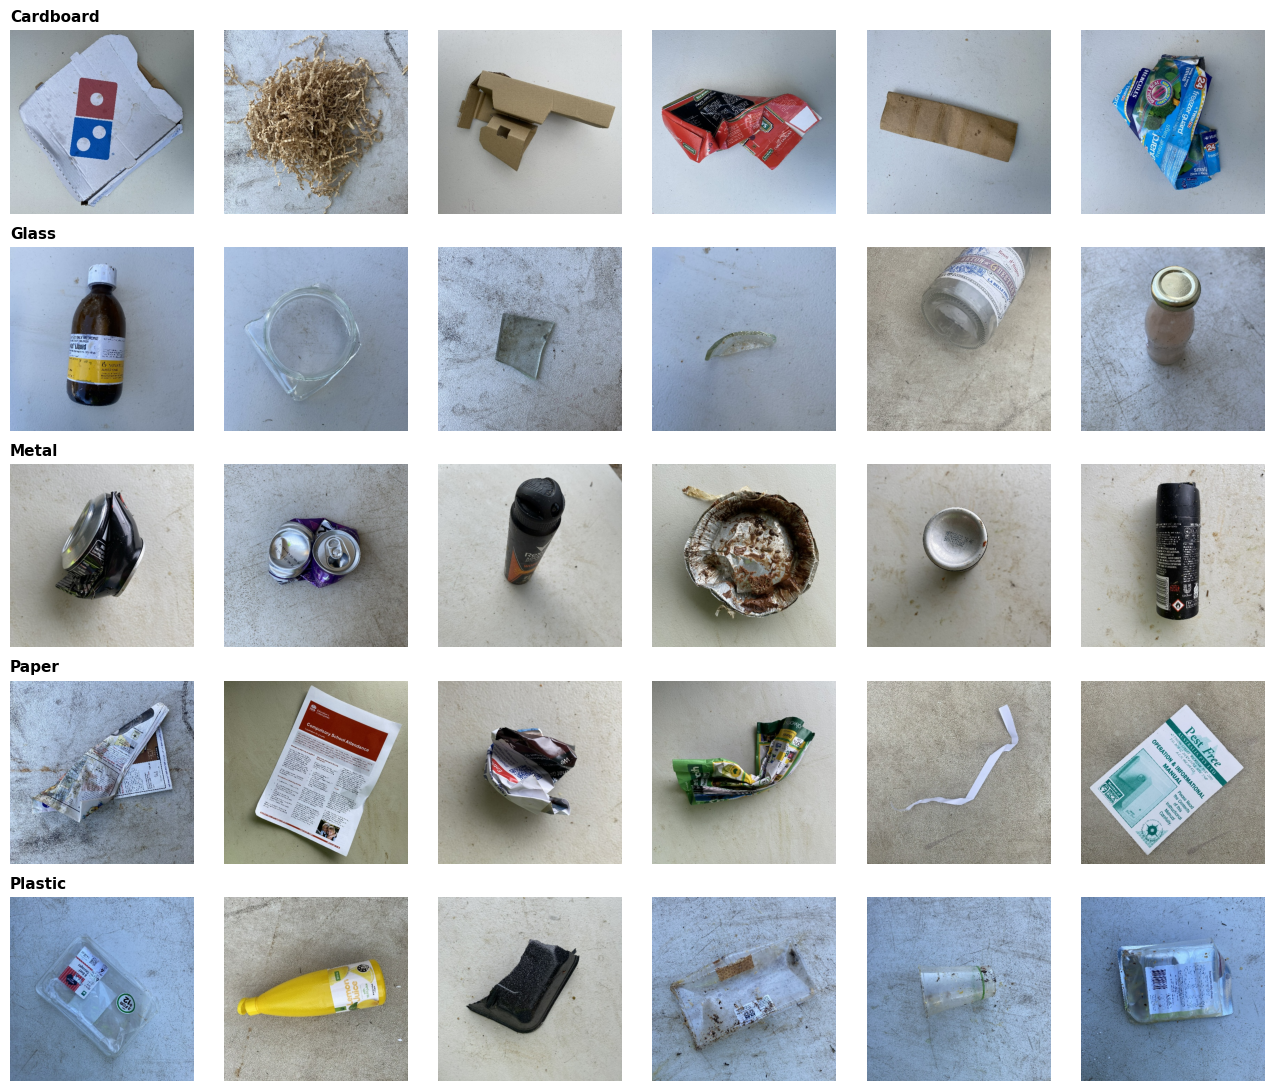

In [ ]:
# sample images from each class
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(13, 2.2*len(CLASSES)))
for i, c in enumerate(CLASSES):
    for j, p in enumerate(random.sample(found[c], 6)):
        axes[i, j].imshow(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)); axes[i, j].axis('off')
    axes[i, 0].set_title(c, loc='left', fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

## Step 3. Training / Validation / Testing split
The split is **stratified** (each class keeps the same proportion in every set) and is done **before** augmentation, so no validation or test image is ever used for training.

In [ ]:
p_tr, p_tmp, y_tr, y_tmp = train_test_split(paths, labels, test_size=SPLIT[1]+SPLIT[2],
                                            stratify=labels, random_state=SEED)
p_va, p_te, y_va, y_te = train_test_split(p_tmp, y_tmp, test_size=SPLIT[2]/(SPLIT[1]+SPLIT[2]),
                                          stratify=y_tmp, random_state=SEED)
assert not (set(p_tr)&set(p_va) or set(p_tr)&set(p_te) or set(p_va)&set(p_te)), 'Leak between sets!'

split_df = pd.DataFrame({
    'Training':   pd.Series(y_tr).map(dict(enumerate(CLASSES))).value_counts(),
    'Validation': pd.Series(y_va).map(dict(enumerate(CLASSES))).value_counts(),
    'Testing':    pd.Series(y_te).map(dict(enumerate(CLASSES))).value_counts()}).loc[CLASSES]
split_df['Total'] = split_df.sum(axis=1); split_df.loc['TOTAL'] = split_df.sum()
display(split_df)
pd.DataFrame({'path': p_tr+p_va+p_te, 'label': y_tr+y_va+y_te,
              'split': ['train']*len(p_tr)+['val']*len(p_va)+['test']*len(p_te)}).to_csv('split.csv', index=False)

,Training,Validation,Testing,Total
Cardboard,323,69,69,461
Glass,294,63,63,420
Metal,553,118,119,790
Paper,350,75,75,500
Plastic,644,139,138,921
TOTAL,2164,464,464,3092


## Step 4. Preprocessing and augmentation
**Preprocessing (every image):** read → decode as 3-channel RGB → resize to 224×224 → scale pixel values to [-1, 1] (done inside the model so the demo uses exactly the same steps).
**Augmentation (training set only):** random flip, rotation, zoom, brightness and contrast, to prepare the model for unseen lighting and viewing angles.

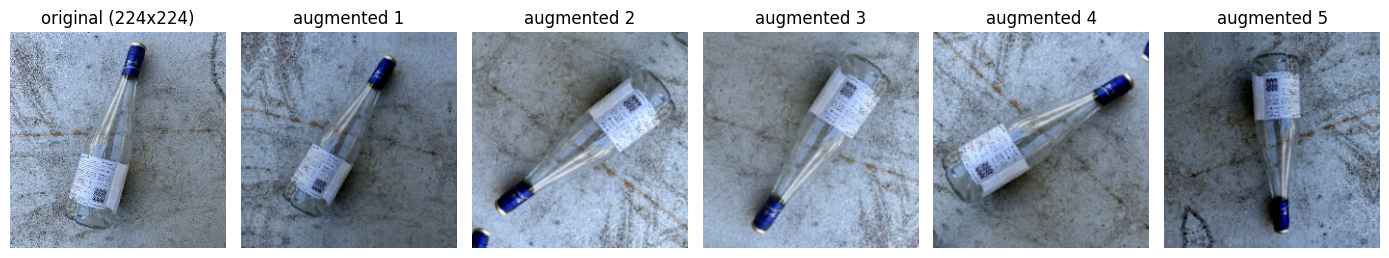

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)   # RGB
    img = tf.image.resize(img, IMG_SIZE, antialias=True)                 # 224x224
    img.set_shape((*IMG_SIZE, 3))
    return img, label                                                    # float32, 0-255

def make_ds(p, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((p, np.array(y, dtype=np.int32)))
    if shuffle: ds = ds.shuffle(len(p), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(p_tr, y_tr, shuffle=True)
val_ds   = make_ds(p_va, y_va)
test_ds  = make_ds(p_te, y_te)          # not shuffled, so predictions line up with y_te

augment = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomBrightness(0.2, value_range=(0, 255)),
    layers.RandomContrast(0.2),
], name='augmentation')

# preview: one image, original vs. augmented versions
img0 = cv2.cvtColor(cv2.imread(p_tr[0]), cv2.COLOR_BGR2RGB)
x0 = tf.image.resize(img0, IMG_SIZE)[None].numpy().astype('float32')
fig, axes = plt.subplots(1, 6, figsize=(14, 2.6))
axes[0].imshow(x0[0].astype('uint8')); axes[0].set_title('original (224x224)')
for k in range(1, 6):
    axes[k].imshow(augment(x0, training=True)[0].numpy().clip(0,255).astype('uint8')); axes[k].set_title(f'augmented {k}')
for a in axes: a.axis('off')
plt.tight_layout(); plt.show()

## Step 5. Model and training
**Model:** MobileNetV2 pre-trained on ImageNet (transfer learning) + global average pooling + dropout + a 5-way softmax layer.
**Stage 1:** train only the new top layers. **Stage 2:** fine-tune the upper part of MobileNetV2 at a low learning rate.
Class weights compensate for the imbalance between classes (e.g. Plastic vs Glass).

In [ ]:
def build_model(num_classes):
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = augment(inputs)                               # active only while training
    x = layers.Rescaling(1/127.5, offset=-1)(x)       # pixel values -> [-1, 1]
    base = keras.applications.MobileNetV2(input_shape=(*IMG_SIZE, 3), include_top=False, weights=WEIGHTS)
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    return keras.Model(inputs, outputs), base

model, base = build_model(len(CLASSES))
cw = compute_class_weight('balanced', classes=np.arange(len(CLASSES)), y=np.array(y_tr))
class_weight = dict(enumerate(cw)); print('class weights:', {CLASSES[k]: round(v,2) for k,v in class_weight.items()})

callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
             keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1)]

model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
t0 = time.time()
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, class_weight=class_weight, callbacks=callbacks)
print(f'Stage 1 done in {(time.time()-t0)/60:.1f} min')

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
class weights: {'Cardboard': np.float64(1.34), 'Glass': np.float64(1.47), 'Metal': np.float64(0.78), 'Paper': np.float64(1.24), 'Plastic': np.float64(0.67)}
Epoch 1/12
68/68 ━━━━━━━━━━━━━━━━━━━━ 22s 219ms/step - accuracy: 0.4422 - loss: 1.3255 - val_accuracy: 0.6789 - val_loss: 0.8391 - learning_rate: 0.0010
Epoch 2/12
68/68 ━━━━━━━━━━━━━━━━━━━━ 13s 186ms/step - accuracy: 0.6437 - loss: 0.8353 - val_accuracy: 0.7392 - val_loss: 0.6913 - learning_rate: 0.0010
Epoch 3/12
68/68 ━━━━━━━━━━━━━━━━━━━━ 13s 192ms/step - accuracy: 0.7066 - loss: 0.7202 - val_accuracy: 0.7543 - val_loss: 0.6373 - learning_rate: 0.0010
Epoch 4/12
68/68 ━━━━━━━━━━━━━━━━━━━━ 14s 201ms/step - accuracy: 0.7232 - loss: 0.6864 - val_accuracy: 0.7802 - val_loss: 0.5732 - learning_rate: 0.0010
Epoch 5/12
68/68 ━━━━━━━━━━━━━━━━━━━━ 20s 190ms/step - accuracy: 0.7569 - loss: 0.6330 - val_accuracy: 0.8039 - val_loss: 0.5480 - learning_rate: 0.0010
Epoch 6/12
68/68 ━━━━━━━━━━━━

In [ ]:
# Stage 2: fine-tune the last layers of MobileNetV2 (BatchNorm layers stay frozen)
base.trainable = True
for layer in base.layers[:-40]: layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization): layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
t0 = time.time()
hist2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT, class_weight=class_weight, callbacks=callbacks)
print(f'Stage 2 done in {(time.time()-t0)/60:.1f} min')

Epoch 1/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 22s 218ms/step - accuracy: 0.8073 - loss: 0.4823 - val_accuracy: 0.8319 - val_loss: 0.4588 - learning_rate: 1.0000e-05
Epoch 2/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 14s 202ms/step - accuracy: 0.8175 - loss: 0.4528 - val_accuracy: 0.8362 - val_loss: 0.4300 - learning_rate: 1.0000e-05
Epoch 3/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 14s 211ms/step - accuracy: 0.8309 - loss: 0.4208 - val_accuracy: 0.8341 - val_loss: 0.4211 - learning_rate: 1.0000e-05
Epoch 4/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 21s 215ms/step - accuracy: 0.8313 - loss: 0.4023 - val_accuracy: 0.8276 - val_loss: 0.4130 - learning_rate: 1.0000e-05
Epoch 5/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 14s 209ms/step - accuracy: 0.8424 - loss: 0.3684 - val_accuracy: 0.8254 - val_loss: 0.4177 - learning_rate: 1.0000e-05
Epoch 6/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 20s 196ms/step - accuracy: 0.8558 - loss: 0.3471 - val_accuracy: 0.8405 - val_loss: 0.3910 - learning_rate: 1.0000e-05
Epoch 7/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 14s 198ms/step - acc

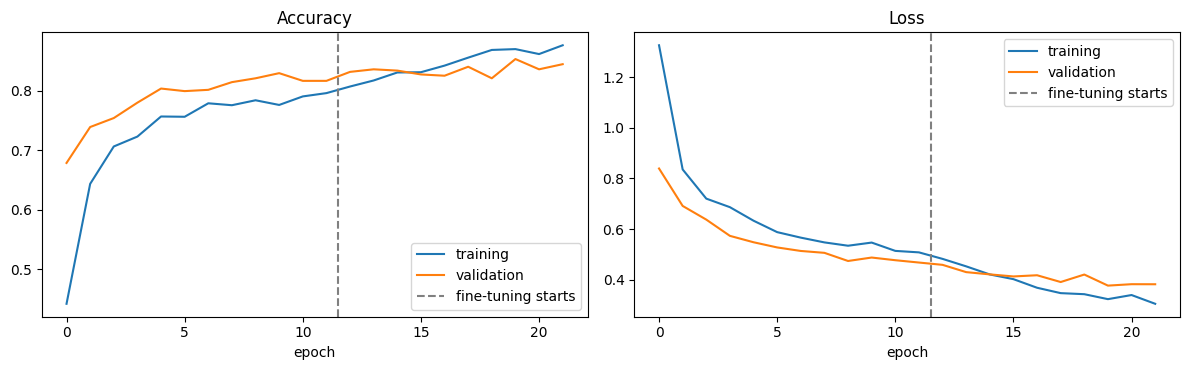

In [ ]:
# training curves (both stages joined)
acc  = hist1.history['accuracy']     + hist2.history['accuracy']
vacc = hist1.history['val_accuracy'] + hist2.history['val_accuracy']
loss = hist1.history['loss']         + hist2.history['loss']
vlos = hist1.history['val_loss']     + hist2.history['val_loss']
n1 = len(hist1.history['loss'])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, (t, v, name) in zip(ax, [(acc, vacc, 'Accuracy'), (loss, vlos, 'Loss')]):
    a.plot(t, label='training'); a.plot(v, label='validation')
    a.axvline(n1-0.5, color='gray', ls='--', label='fine-tuning starts'); a.set_title(name); a.set_xlabel('epoch'); a.legend()
plt.tight_layout(); plt.show()

## Step 6. Evaluation on the Testing set
The test images were never used for training or for choosing when to stop training.

In [ ]:
probs  = model.predict(test_ds, verbose=0)
y_pred = probs.argmax(1); y_true = np.array(y_te)
test_acc = accuracy_score(y_true, y_pred)
print(f'TEST ACCURACY: {test_acc*100:.2f}%   ({(y_true==y_pred).sum()} of {len(y_true)} images correct)\n')

rep = classification_report(y_true, y_pred, target_names=CLASSES, output_dict=True, digits=4, zero_division=0)
rep_df = pd.DataFrame(rep).T.round(4)
rep_df.loc['accuracy', ['precision','recall']] = np.nan; rep_df.loc['accuracy','f1-score'] = round(test_acc, 4); rep_df.loc['accuracy','support'] = len(y_true)
rep_df['support'] = rep_df['support'].astype(int)
display(rep_df)
print('Macro F1:', round(rep['macro avg']['f1-score'], 4), '| Weighted F1:', round(rep['weighted avg']['f1-score'], 4))

TEST ACCURACY: 88.15%   (409 of 464 images correct)



,precision,recall,f1-score,support
Cardboard,0.8939,0.8551,0.8741,69
Glass,0.8615,0.8889,0.8750,63
Metal,0.8974,0.8824,0.8898,119
Paper,0.8372,0.9600,0.8944,75
Plastic,0.9000,0.8478,0.8731,138
accuracy,NaN,NaN,0.8815,464
macro avg,0.8780,0.8868,0.8813,464
weighted avg,0.8831,0.8815,0.8812,464


Macro F1: 0.8813 | Weighted F1: 0.8812


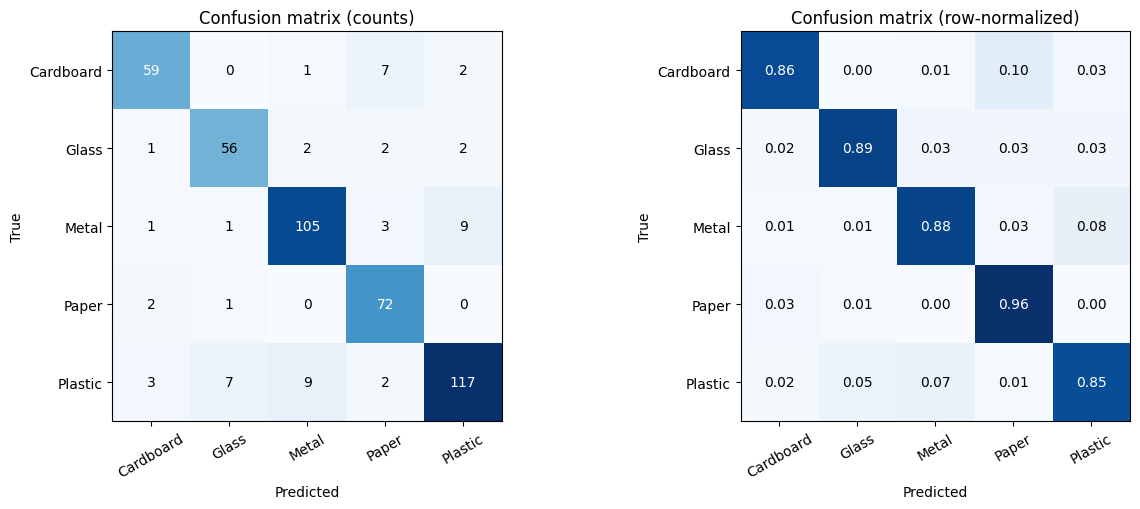

Most common mistakes (true -> predicted : count):
  Metal -> Plastic : 9
  Plastic -> Metal : 9
  Cardboard -> Paper : 7
  Plastic -> Glass : 7
  Metal -> Paper : 3


In [ ]:
cm  = confusion_matrix(y_true, y_pred)
cmn = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, M, title, fmt in [(axes[0], cm, 'Confusion matrix (counts)', 'd'), (axes[1], cmn, 'Confusion matrix (row-normalized)', '.2f')]:
    im = ax.imshow(M, cmap='Blues'); ax.set_title(title)
    ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=30); ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, format(M[i, j], fmt), ha='center', va='center', color='white' if M[i, j] > M.max()/2 else 'black')
plt.tight_layout(); plt.savefig('confusion_matrix.png', dpi=150); plt.show()

# most confused pairs
pairs = [(CLASSES[i], CLASSES[j], int(cm[i, j])) for i in range(len(CLASSES)) for j in range(len(CLASSES)) if i != j and cm[i, j] > 0]
print('Most common mistakes (true -> predicted : count):')
for t, p, n in sorted(pairs, key=lambda x: -x[2])[:5]: print(f'  {t} -> {p} : {n}')

55 misclassified test images; showing up to 10


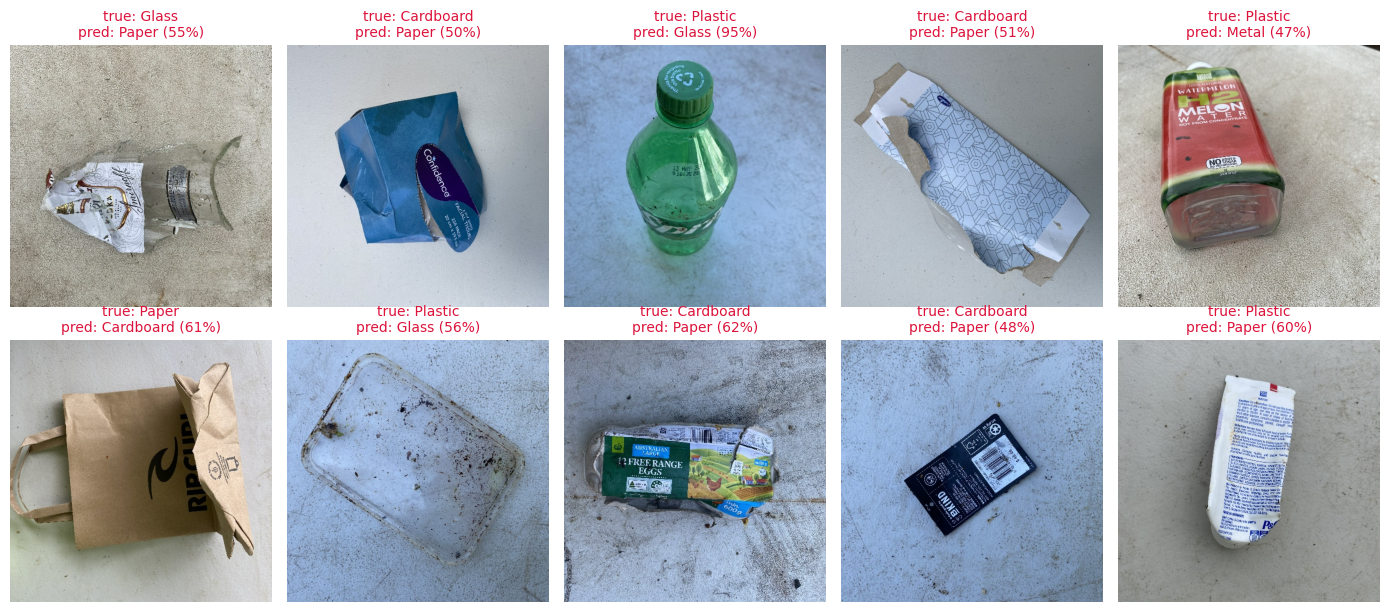

In [ ]:
# examples the model got wrong
wrong = np.where(y_pred != y_true)[0]
print(f'{len(wrong)} misclassified test images; showing up to 10')
sel = wrong[:10]
if len(sel):
    fig, axes = plt.subplots(2, 5, figsize=(14, 6.2))
    for a in axes.ravel(): a.axis('off')
    for a, k in zip(axes.ravel(), sel):
        a.imshow(cv2.cvtColor(cv2.imread(p_te[k]), cv2.COLOR_BGR2RGB))
        a.set_title(f'true: {CLASSES[y_true[k]]}\npred: {CLASSES[y_pred[k]]} ({probs[k].max()*100:.0f}%)', fontsize=10, color='crimson')
    plt.tight_layout(); plt.show()

## Step 7. Demonstration: Image → Preprocessing → Model → Recognition → Visual output
`recognize()` runs the whole pipeline on one image and draws the **class label and confidence score** on it. It works with a file path or a camera frame, so it can be used on images chosen by the instructor.

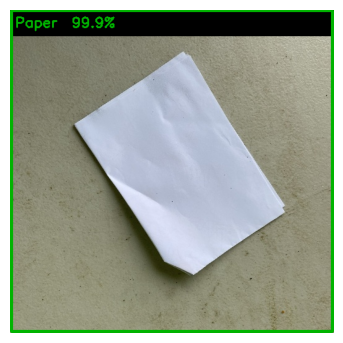

Cardboard: 0.1%  Glass: 0.0%  Metal: 0.0%  Paper: 99.9%  Plastic: 0.0%
TRUE: Paper | PREDICTED: Paper 



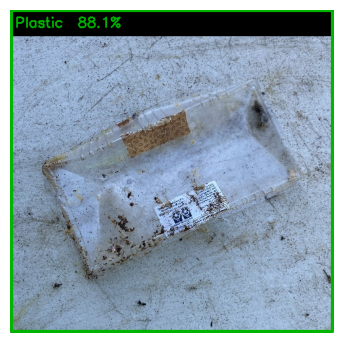

Cardboard: 8.0%  Glass: 3.7%  Metal: 0.0%  Paper: 0.1%  Plastic: 88.1%
TRUE: Plastic | PREDICTED: Plastic 



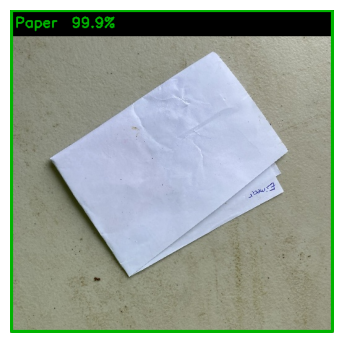

Cardboard: 0.0%  Glass: 0.0%  Metal: 0.0%  Paper: 99.9%  Plastic: 0.0%
TRUE: Paper | PREDICTED: Paper 



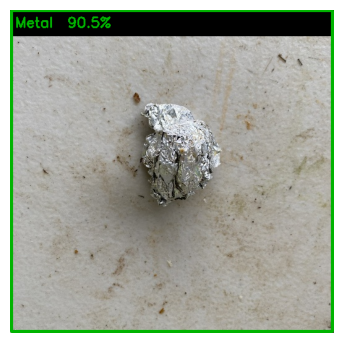

Cardboard: 2.2%  Glass: 1.3%  Metal: 90.5%  Paper: 2.2%  Plastic: 3.8%
TRUE: Metal | PREDICTED: Metal 



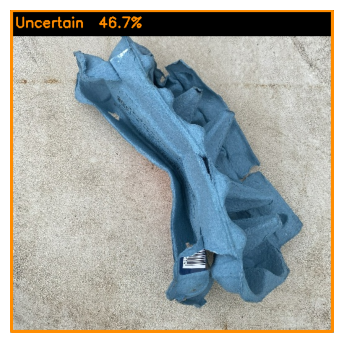

Cardboard: 13.4%  Glass: 8.5%  Metal: 2.4%  Paper: 46.7%  Plastic: 29.1%
TRUE: Cardboard | PREDICTED: Uncertain 



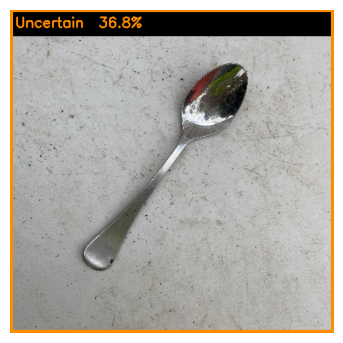

Cardboard: 2.2%  Glass: 32.9%  Metal: 28.0%  Paper: 0.1%  Plastic: 36.8%
TRUE: Metal | PREDICTED: Uncertain 



In [ ]:
def recognize(source, show=True):
    """source: image path or a BGR numpy array (e.g. a camera frame). Returns (label, confidence, annotated BGR image)."""
    bgr = cv2.imread(str(source)) if isinstance(source, (str, Path)) else source.copy()
    assert bgr is not None, f'Could not read {source}'
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)                       # preprocessing: BGR -> RGB
    x   = cv2.resize(rgb, IMG_SIZE, interpolation=cv2.INTER_AREA)    # preprocessing: resize 224x224
    p   = model.predict(x[None].astype('float32'), verbose=0)[0]     # model (scaling to [-1,1] is inside the model)
    k, conf = int(p.argmax()), float(p.max())                        # recognition
    label = CLASSES[k] if conf >= CONF_THRESH else 'Uncertain'
    out = bgr.copy(); h, w = out.shape[:2]
    color = (0, 180, 0) if label != 'Uncertain' else (0, 140, 255)
    cv2.rectangle(out, (0, 0), (w, max(34, h//12)), (0, 0, 0), -1)
    cv2.putText(out, f'{label}  {conf*100:.1f}%', (8, max(24, h//18)), cv2.FONT_HERSHEY_SIMPLEX, max(0.6, w/700), color, 2)
    cv2.rectangle(out, (2, 2), (w-3, h-3), color, 3)                 # visual output
    if show:
        plt.figure(figsize=(4.2, 4.2)); plt.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()
        print('  '.join(f'{c}: {v*100:.1f}%' for c, v in zip(CLASSES, p)))
    return label, conf, out

# demo on random images from the Testing set
for k in random.sample(range(len(p_te)), 6):
    label, conf, _ = recognize(p_te[k]); print('TRUE:', CLASSES[y_te[k]], '| PREDICTED:', label, '\n')

### 7a. Try your own / the instructor's images
Run the next cell and select one or more images (JPG/PNG). Each is classified and shown with its label and confidence.

Saving plastic-bottle.jpg to plastic-bottle.jpg
== plastic-bottle.jpg


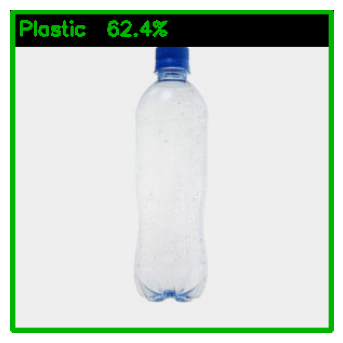

Cardboard: 2.6%  Glass: 34.6%  Metal: 0.3%  Paper: 0.1%  Plastic: 62.4%


In [ ]:
if IN_COLAB:
    from google.colab import files
    up = files.upload()
    for name in up: print('==', name); recognize(name)
else:
    print('Upload demo only runs in Colab. Call recognize("path/to/image.jpg") instead.')

### 7b. Live camera input (Colab webcam)
Run the cell, allow camera access in the browser, then click **Capture**. The photo goes through the same pipeline. Run the cell again for another photo.

<IPython.core.display.Javascript object>

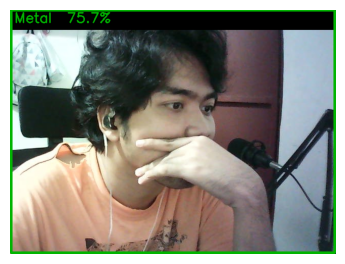

Cardboard: 7.1%  Glass: 2.9%  Metal: 75.7%  Paper: 13.9%  Plastic: 0.4%


In [ ]:
def capture_from_webcam(filename='webcam.jpg', quality=0.9):
    from IPython.display import display, Javascript
    from google.colab.output import eval_js
    from base64 import b64decode
    js = Javascript('''
      async function takePhoto(quality) {
        const div = document.createElement('div');
        const btn = document.createElement('button'); btn.textContent = 'Capture'; div.appendChild(btn);
        const video = document.createElement('video'); video.style.display = 'block';
        const stream = await navigator.mediaDevices.getUserMedia({video: true});
        document.body.appendChild(div); div.appendChild(video); video.srcObject = stream; await video.play();
        google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
        await new Promise((resolve) => btn.onclick = resolve);
        const canvas = document.createElement('canvas'); canvas.width = video.videoWidth; canvas.height = video.videoHeight;
        canvas.getContext('2d').drawImage(video, 0, 0);
        stream.getVideoTracks()[0].stop(); div.remove();
        return canvas.toDataURL('image/jpeg', quality);
      }''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    with open(filename, 'wb') as f: f.write(b64decode(data.split(',')[1]))
    return filename

if IN_COLAB:
    try:
        recognize(capture_from_webcam())
    except Exception as e:
        print('Webcam not available:', e)
else:
    print('Webcam demo only runs in Colab. For a local webcam use cv2.VideoCapture(0) and pass the frame to recognize().')

### 7c. Unseen-situation test (optional but recommended)
Take your own photos of the 5 classes under **different lighting, backgrounds and angles**, and put them in a folder with one sub-folder per class, e.g.

```
my_photos/
    Cardboard/  img1.jpg ...
    Glass/      ...
    Metal/      ...
    Paper/      ...
    Plastic/    ...
```
Zip the folder as `my_photos.zip`, set `MY_PHOTOS_ZIP` below and run the cell. The result is your accuracy on data that is truly unseen. If the file is not found, the cell is skipped.

In [ ]:
MY_PHOTOS_ZIP = 'my_photos.zip'     # upload this file to the Colab file panel (left side) first

if os.path.exists(MY_PHOTOS_ZIP):
    mp = Path('my_photos'); shutil.rmtree(mp, ignore_errors=True)
    with zipfile.ZipFile(MY_PHOTOS_ZIP) as z: z.extractall(mp)
    ip, iy = [], []
    for d in mp.rglob('*'):
        if d.is_dir() and d.name in CLASSES:
            for f in images_in(d): ip.append(str(f)); iy.append(CLASSES.index(d.name))
    print(f'{len(ip)} unseen images found')
    if ip:
        ids = make_ds(ip, iy); pr = model.predict(ids, verbose=0).argmax(1)
        print(f'UNSEEN-IMAGE ACCURACY: {accuracy_score(iy, pr)*100:.2f}%')
        print(classification_report(iy, pr, labels=range(len(CLASSES)), target_names=CLASSES, zero_division=0))
else:
    print('No my_photos.zip found - skipping (optional).')

## Step 8. Save the model and a results summary

In [ ]:
model.save('waste_classifier.keras')
json.dump(CLASSES, open('class_names.json', 'w'))
results = {'classes': CLASSES, 'images_per_class': counts.to_dict(), 'split': {'train': len(p_tr), 'val': len(p_va), 'test': len(p_te)},
           'test_accuracy': round(float(test_acc), 4), 'macro_f1': round(rep['macro avg']['f1-score'], 4),
           'per_class_f1': {c: round(rep[c]['f1-score'], 4) for c in CLASSES}}
json.dump(results, open('results.json', 'w'), indent=2); print(json.dumps(results, indent=2))

print('\n=== COPY INTO THE REPORT / PRESENTATION ===')
print(f'Dataset: RealWaste subset, {len(CLASSES)} classes ({", ".join(CLASSES)}), {len(paths)} images')
print(f'Split: {len(p_tr)} training / {len(p_va)} validation / {len(p_te)} testing')
print(f'Model: MobileNetV2 (ImageNet transfer learning), input {IMG_SIZE[0]}x{IMG_SIZE[1]}')
print(f'Test accuracy: {test_acc*100:.2f}% | Macro F1: {rep["macro avg"]["f1-score"]:.4f}')
if IN_COLAB:
    from google.colab import files
    for f in ['waste_classifier.keras', 'class_names.json', 'results.json', 'confusion_matrix.png', 'split.csv']: files.download(f)

{
  "classes": [
    "Cardboard",
    "Glass",
    "Metal",
    "Paper",
    "Plastic"
  ],
  "images_per_class": {
    "Cardboard": 461,
    "Glass": 420,
    "Metal": 790,
    "Paper": 500,
    "Plastic": 921
  },
  "split": {
    "train": 2164,
    "val": 464,
    "test": 464
  },
  "test_accuracy": 0.8815,
  "macro_f1": 0.8813,
  "per_class_f1": {
    "Cardboard": 0.8741,
    "Glass": 0.875,
    "Metal": 0.8898,
    "Paper": 0.8944,
    "Plastic": 0.8731
  }
}

=== COPY INTO THE REPORT / PRESENTATION ===
Dataset: RealWaste subset, 5 classes (Cardboard, Glass, Metal, Paper, Plastic), 3092 images
Split: 2164 training / 464 validation / 464 testing
Model: MobileNetV2 (ImageNet transfer learning), input 224x224
Test accuracy: 88.15% | Macro F1: 0.8813


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Notes for the report
* Put the **test accuracy, the classification report table and the confusion matrix** from Step 6 into your Results section.
* Say that the dataset is public (RealWaste), the model is a **pre-trained MobileNetV2** (ImageNet) fine-tuned by the group, and cite both (see References in the report). The project brief penalizes undocumented external datasets, code or models.
* If the instructor gives you test images, run `recognize("image.jpg")` (Step 7) live. Do not only show saved results.